# 06· Modelo de Machine Learning: Random Forest con rezagos 

Este notebook entrena el modelo de machine learning del proyecto: un **Random Forest** que pronostica la varianza diaria del WTI (estimador de Parkinson del día τ) a partir de rezagos y medidas móviles de volatilidad, con información disponible hasta τ−1. Se evalúa en los mismos 10 folds de Time Series Cross-Validation que el modelo econométrico AR-EGARCH, para compararlos en exactamente los mismos días.

**Contenido**

0. Configuración
1. Carga de datos, folds y selección de variables
2. Especificación del modelo y del pipeline
3. Funciones de evaluación
4. Optimización de hiperparámetros con Optuna
5. Gráficas de la optimización: historial, curva de validación y curva de aprendizaje
6. Errores del modelo final por fold (train y validación)
7. Gráficas de resultados
8. Guardar resultados
9. Conclusiones
10. Referencias

## 0. Configuración

In [1]:
import sys
import warnings
from pathlib import Path

In [2]:
# Raíz del proyecto (funciona desde la raíz o desde notebooks/)
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))
from src import config as cfg

In [3]:


import importlib
import re
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from src import random_forest as rf

import optuna
import time

import joblib

from optuna.visualization.matplotlib import (plot_optimization_history, plot_param_importances,
                                             plot_slice)

C:\Users\ASUS\Desktop\Maestria IA USFQ\AprendizajeSupervisado\Proyectofinal_ml_wti\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
importlib.reload(rf)

<module 'src.random_forest' from 'c:\\Users\\ASUS\\Desktop\\Maestria IA USFQ\\AprendizajeSupervisado\\Proyectofinal_ml_wti\\src\\random_forest.py'>

In [5]:
PROC = RAIZ / "data" / "processed"
RES_DIR = RAIZ / "results"
FIG_DIR = RAIZ / "figures"
RES_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
FS_DIR = PROC / "feature_selection"

SEED = 42

### Configuración de parámetros de visualización
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
warnings.filterwarnings("ignore", category=FutureWarning)

## 1. Carga de datos, folds y selección de variables


- `X`: 67 variables candidatas construidas por extracción de rezagos . Cada fila τ usa información hasta τ−1.
- `y`: la volatilidad estimada por medio de Parkinson en el día  τ (%²), variable objetivo.
- `FOLDS`: 10 folds de Time Series Cross-Validation (2 repeticiones × 5 folds, ventana expansiva).
- `K_FINAL`: número de variables elegido en la selección de variables.
- `MI_FOLD`: información mutua de cada variable calculada con el entrenamiento de cada fold.

In [6]:
PROC

WindowsPath('c:/Users/ASUS/Desktop/Maestria IA USFQ/AprendizajeSupervisado/Proyectofinal_ml_wti/data/processed')

In [7]:

X = pd.read_csv(PROC / "fe_features_X.csv", index_col=0, parse_dates=True)

y_df = pd.read_csv(PROC / "fe_features_y.csv", index_col=0, parse_dates=True)
y = y_df.iloc[:, 0]
y.name = "WTI_park"

X, y = X.align(y, join="inner", axis=0)     # mismas fechas y mismo orden

# 2. Folds de Time Series Cross-Validation
FOLDS = pd.read_csv(PROC / "folds.csv",
                    parse_dates=["train_ini", "train_fin", "val_ini", "val_fin"])

Se cargan los puntajes de información mutua calculados durante la selección de variables y se organizan en el mismo orden de las columnas de X. En cada fold, estos puntajes permiten que SelectKBest seleccione las 16 variables que muestran mayor dependencia estadística con la variable objetivo dentro del entrenamiento correspondiente. Así, el Random Forest se ajusta con las variables seleccionadas y los puntajes disponibles, manteniendo la selección coherente con cada fold de validación.

In [8]:

config_fs = json.loads((FS_DIR / "fs_config.json").read_text(encoding="utf-8"))
K_FINAL = config_fs["k"]                                            # 16

mi_por_fold = pd.read_csv(FS_DIR / "fs_mi_por_fold.csv", index_col=0)
MI_FOLD = [mi_por_fold[c].reindex(X.columns).to_numpy() for c in mi_por_fold.columns]

In [9]:
assert set(mi_por_fold.index) == set(X.columns), "X no tiene las mismas columnas que en feature selection"
assert len(MI_FOLD) == len(FOLDS)
assert X.notna().all().all() and y.notna().all()

print(f"X: {X.shape} | y: {y.shape} | {X.index.min().date()} → {X.index.max().date()}")
print(f"k (feature selection): {K_FINAL} | folds: {len(FOLDS)}")

X: (3706, 67) | y: (3706,) | 2010-04-07 → 2024-12-31
k (feature selection): 16 | folds: 10


`X` y `y` tienen 3.706 observaciones alineadas por fecha, desde el 7 de abril de 2010 hasta el 31 de diciembre de 2024. `X` contiene 67 variables candidatas y `y` una variable objetivo por observación. El valor `k = 16` indica que el pipeline seleccionará 16 variables para entrenar el Random Forest. 

¿Por qué `k = 16`?  Se eligió \(k=16\) porque, en el cuaderno `05.feature_selection.ipynb`, se comparó el desempeño del Random Forest con distintos valores de \(k\) mediante validación temporal. En cada fold se calcularon el MSE y el QLIKE sobre el periodo de validación; después, para cada valor de \(k\), se resumieron ambas métricas mediante su media y desviación estándar entre folds. La comparación mostró que \(k=16\) obtuvo el menor error según el criterio de selección utilizado. Por ello, en este notebook `SelectKBest` conserva las 16 variables con mayor información mutua calculada con los datos de entrenamiento de cada fold, y el Random Forest se entrena y evalúa con esa selección.

La evaluación se hará en 10 folds de validación temporal que se muestran a continuación:

In [10]:
# Índices de entrenamiento y validación de cada fold (por fechas)
CV = []
for f in FOLDS.itertuples():
    tr = np.where(rf.mascara(X.index, f.train_ini, f.train_fin))[0]
    va = np.where(rf.mascara(X.index, f.val_ini, f.val_fin))[0]
    CV.append((f.rep, f.fold, tr, va))

for rep, fold, tr, va in CV:
    print(f"R{rep}·F{fold}: train {X.index[tr[0]].date()} → {X.index[tr[-1]].date()} ({len(tr)}) | "
          f"val {X.index[va[0]].date()} → {X.index[va[-1]].date()} ({len(va)})")

R1·F1: train 2010-04-07 → 2019-12-31 (2450) | val 2020-01-02 → 2020-12-31 (251)
R1·F2: train 2010-04-07 → 2020-12-31 (2701) | val 2021-01-04 → 2021-12-31 (252)
R1·F3: train 2010-04-07 → 2021-12-31 (2953) | val 2022-01-03 → 2022-12-30 (251)
R1·F4: train 2010-04-07 → 2022-12-30 (3204) | val 2023-01-03 → 2023-12-29 (250)
R1·F5: train 2010-04-07 → 2023-12-29 (3454) | val 2024-01-02 → 2024-12-31 (252)
R2·F1: train 2010-04-07 → 2019-06-28 (2322) | val 2019-07-01 → 2020-06-30 (251)
R2·F2: train 2010-04-07 → 2020-06-30 (2573) | val 2020-07-01 → 2021-06-30 (252)
R2·F3: train 2010-04-07 → 2021-06-30 (2825) | val 2021-07-01 → 2022-06-30 (252)
R2·F4: train 2010-04-07 → 2022-06-30 (3077) | val 2022-07-01 → 2023-06-30 (251)
R2·F5: train 2010-04-07 → 2023-06-30 (3328) | val 2023-07-03 → 2024-06-28 (250)


La validación temporal se organiza en **10 folds: dos repeticiones de cinco folds cada una**, con ventanas de entrenamiento expansivas. En todos los folds, el entrenamiento comienza el 7 de abril de 2010 y se amplía al avanzar en el tiempo; cada periodo de validación contiene aproximadamente 250 días hábiles.

En la **repetición 1**, los cinco periodos de validación corresponden a los años calendario de 2020 a 2024. En la **repetición 2**, la validación usa ventanas de aproximadamente un año que van de julio a junio, desde julio de 2019 hasta junio de 2024. En cada fold, el modelo se entrena únicamente con datos anteriores al periodo de validación y se evalúa con los datos de ese periodo, respetando así el orden temporal y evitando entrenar con información futura.

## 2. Especificación del modelo y del pipeline

**Random Forest.** Conjunto de árboles de regresión entrenados sobre muestras *bootstrap* del entrenamiento; cada árbol considera en cada división una fracción aleatoria de las variables. El pronóstico es el promedio de los árboles, lo que reduce la varianza frente a un único árbol y permite capturar relaciones no lineales entre la volatilidad pasada y la futura.

Se puede aplicar a series temporales cuando las observaciones se representan mediante variables predictoras construidas con información pasada, como rezagos y medidas móviles. En este caso se llama Random Forest con rezagos porque esas variables describen valores anteriores de la serie y se usan para pronosticar la varianza estimada de Parkinson del día objetivo. La validación conserva el orden temporal: cada modelo se entrena con datos anteriores al periodo que debe pronosticar.

**Pipeline.** El modelo se implementa como un `Pipeline` (flujo de pasos) de scikit-learn con dos pasos:

1. `SelectKBest(mutual_info_regression, k=16)`: selección tipo *filter* de las 16 variables con mayor información mutua.
2. `RandomForestRegressor`: modelo de regresión.

En cada fold, `pipeline.fit(X_train, y_train)` ajusta **ambos pasos solo con el entrenamiento**: la información mutua se calcula con esos días y el Random Forest se entrena con las variables elegidas. Luego `pipeline.predict(X_val)` aplica la misma selección y el modelo ya entrenado a la validación, sin volver a ajustar nada. Así no hay fuga de información desde la validación.

**Variable objetivo.** Se entrena directamente sobre el Parkinson del día τ (%²), sin transformación logarítmica. El MSE y la QLIKE se minimizan cuando el pronóstico es la media condicional de la varianza; con logaritmo, el modelo estimaría la media de ln(y) y al deshacer la transformación subestimaría la varianza de forma sistemática. La influencia de los días extremos (2020) se controla con `min_samples_leaf`.

**Funciones de pérdida** (en cada día objetivo τ de la validación):
- $\text{MSE} = (\sigma^2_{P,\tau} - \hat\sigma^2_\tau)^2$
- $\text{QLIKE} = \dfrac{\sigma^2_{P,\tau}}{\hat\sigma^2_\tau} + \ln \hat\sigma^2_\tau$, robusta al ruido del proxy (Patton, 2011). Es la métrica principal.


Se considera Qlike porque tiene la ventaja de basarse en el error relativo y ser menos sensible, en general, a observaciones extremas y a la escala de la volatilidad. 

- **Funciones de pérdida** (para cada día objetivo $\tau$ de validación). $\sigma^2_{P,\tau}$ es la varianza estimada con Parkinson y se usa como **proxy**: una medida observada que aproxima la volatilidad verdadera, que no se observa directamente. $\hat{\sigma}^2_\tau$ es la varianza pronosticada por el modelo.

  - $\text{MSE}_\tau = (\sigma^2_{P,\tau} - \hat{\sigma}^2_\tau)^2$. Penaliza el error absoluto al cuadrado, por lo que los errores grandes —frecuentes en períodos de alta volatilidad— pueden pesar mucho en el promedio.
  - $\text{QLIKE}_\tau = \dfrac{\sigma^2_{P,\tau}}{\hat{\sigma}^2_\tau} + \ln(\hat{\sigma}^2_\tau)$. Evalúa el pronóstico en relación con el nivel de varianza observado. En este estudio se usa como **métrica principal** porque es adecuada para comparar pronósticos de varianza y, en general, es menos sensible que MSE a observaciones extremas y a la escala de la volatilidad. MSE se conserva como métrica complementaria. Valores menores indican mejor desempeño.

El ruido del proxy significa que la estimación de Parkinson puede diferir de la varianza verdadera. La robustez se refiere a que, bajo ciertas condiciones, el ranking de los pronósticos puede conservarse pese a ese ruido; no significa que QLIKE elimine el ruido.





## 3. Funciones de evaluación

- `perdidas`: MSE y QLIKE diarios.
- `crear_pipeline`: arma el pipeline selección + Random Forest con los hiperparámetros indicados.
- `CV`: índices de entrenamiento y validación de cada fold, definidos por fechas (los mismos días que el EGARCH).
- `puntajes_fijos`: permite que `SelectKBest` use la información mutua ya calculada en el notebook 05 durante la búsqueda de Optuna. Es idéntico a recalcularla, pero evita repetir el mismo cálculo en cada prueba.

<a id="optuna"></a>
##  4. Optimización de hiperparámetros con Optuna

Se buscan los hiperparámetros del Random Forest que minimizan la **QLIKE promedio de validación en los 10 folds**. Esta validación cruzada para series de tiempo (ventana expansiva, 2 repeticiones × 5 folds) sustituye al *repeated k-fold* tradicional, que no es válido en series de tiempo porque usaría observaciones futuras para entrenar. El número de variables se mantiene en k = 16, elegido con la misma validación en el notebook de selección de variables.

Estos son los hiperparámetros del `RandomForestRegressor` que se optimizan con Optuna:


| Hiperparámetro | Rango | Qué controla |
|---|---|---|
| `n_estimators` | 100 – 600 | Número de árboles |
| `max_depth` | 2 – 20 | Profundidad máxima de cada árbol (complejidad del modelo) |
| `min_samples_leaf` | 5 – 200 (escala log) | Mínimo de días por hoja; suaviza el efecto de los días extremos |
| `max_features` | 0.2 – 1.0 | Fracción de variables evaluadas en cada división (diversidad entre árboles) |

En cada prueba, y para cada fold, el pipeline se ajusta con `.fit` sobre el entrenamiento y se evalúa con `.predict` sobre la validación. Se usa el muestreador TPE (búsqueda bayesiana) y poda por mediana: si una prueba va peor que la mediana de las anteriores después de varios folds, se detiene para ahorrar tiempo. El estudio se guarda en una base SQLite, de modo que la búsqueda puede retomarse si se interrumpe.

In [11]:
N_TRIALS = 50

study = optuna.create_study(
    direction="minimize",
    study_name="rf_volatilidad_wti",
    storage=f"sqlite:///{RES_DIR / 'optuna_rf.db'}",
    load_if_exists=True,
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=3),
)
pendientes = max(0, N_TRIALS - len(study.trials))
t0 = time.time()
study.optimize(
    lambda trial: rf.objetivo(trial, K_FINAL, MI_FOLD, CV, X, y),
    n_trials=pendientes,
    show_progress_bar=True
)
print(f"Tiempo: {(time.time() - t0) / 60:.1f} min | pruebas: {len(study.trials)}")

estados = pd.Series([t.state.name for t in study.trials]).value_counts()
display(estados.to_frame("pruebas"))
print(f"Mejor QLIKE promedio en validación: {study.best_value:.4f}")

best = dict(study.best_params)
display(pd.Series({"k": K_FINAL, **best}, name="mejores hiperparámetros").to_frame())

[I 2026-11-19 04:13:12,438] Using an existing study with `study_name='rf_volatilidad_wti'` instead of creating a new one.


Tiempo: 0.0 min | pruebas: 50


,pruebas
COMPLETE,34
PRUNED,16


Mejor QLIKE promedio en validación: 2.8487


,mejores hiperparámetros
k,16.000000
n_estimators,350.000000
max_depth,7.000000
min_samples_leaf,10.000000
max_features,0.960372


 Optuna realizó **50 pruebas**: 34 finalizaron y 16 fueron podadas durante la búsqueda. El mejor ensayo obtuvo un **QLIKE promedio de validación de 2.8487** y seleccionó \(k=16\) variables, con `n_estimators=350`, `max_depth=7`, `min_samples_leaf=10` y `max_features≈0.96`. Estos hiperparámetros corresponden a la mejor combinación encontrada entre las pruebas completadas; el QLIKE reportado es el promedio de validación utilizado durante la búsqueda.

## 5. Gráficas de la optimización

- **Curva de entrenamiento y validación:** compara el QLIKE de entrenamiento y validación al variar un determinado hiperparámetro, manteniendo fijos los demás hiperparámetros en sus mejores valores. Una profundidad baja puede producir alto sesgo y subajuste: el modelo es demasiado simple y ambos errores tienden a ser altos. Al aumentar la profundidad, el error de entrenamiento suele bajar; si el QLIKE de validación deja de mejorar o aumenta mientras la brecha entre ambos errores crece, puede indicar alta varianza y sobreajuste. La profundidad con menor QLIKE de validación entre las evaluadas representa el mejor equilibrio observado. La gráfica ayuda a diagnosticar ese comportamiento, aunque no mide directamente sesgo y varianza. Se realiza sobre los 3 hiperparámetros más importantes por Optuna: `min_samples_leaf`, `n_estimators` y `max_depth`. 
- **Historial:** QLIKE de cada prueba y mejor valor acumulado; muestra que la búsqueda converge.
- **Importancia de los hiperparámetros:** cuáles influyen más en el error de validación.
- **Slice:** QLIKE frente a cada hiperparámetro, para ver en qué zona se ubican los mejores valores.
- **Curvas de aprendizaje** : muestran cómo cambia el QLIKE de entrenamiento y validación al variar la cantidad de datos usados para entrenar, manteniendo fijos los hiperparámetros. Permiten evaluar si incorporar más observaciones mejora el desempeño de validación y si la brecha entre ambos errores se reduce o se mantiene. Si el QLIKE de validación baja, más datos están ayudando a generalizar; si se estabiliza, añadir datos aporta poca mejora en los tamaños evaluados.


### Curva de entrenamiento y validación

#### Profundidad máxima

Con los demás hiperparámetros fijos en los mejores valores, se varía `max_depth` y se calcula la QLIKE en entrenamiento y validación (folds de la repetición 1). Árboles poco profundos con error alto en ambos indican **subajuste**; si al aumentar la profundidad el error de entrenamiento sigue bajando pero el de validación no mejora, hay **sobreajuste**.

In [12]:
PROF = [2, 3, 4, 6, 7, 8, 9, 10, 15, 20, 25, 30, 35, 40, 45, 50]

# Seleccionar los folds de la repetición 1
folds_curva = [
    (i, rep, fold, tr, va)
    for i, (rep, fold, tr, va) in enumerate(CV)
]

filas = []

for profundidad in PROF:
    params = {**best, "max_depth": profundidad}

    for i, rep, fold, tr, va in folds_curva:
        pipe = rf.crear_pipeline(
            K_FINAL,
            score_func=rf.puntajes_fijos(MI_FOLD[i]),
            **params
        )
        pipe.fit(X.iloc[tr], y.iloc[tr])

        pred_train = pipe.predict(X.iloc[tr])
        pred_val = pipe.predict(X.iloc[va])

        qlike_train = rf.perdidas(y.iloc[tr], pred_train)["qlike"].mean()
        qlike_val = rf.perdidas(y.iloc[va], pred_val)["qlike"].mean()

        filas.append({
            "max_depth": profundidad,
            "rep": rep,
            "fold": fold,
            "qlike_train": qlike_train,
            "qlike_val": qlike_val,
        })

curva = pd.DataFrame(filas)

resumen_md = curva.groupby("max_depth").agg(
    qlike_train_mean=("qlike_train", "mean"),
    qlike_train_std=("qlike_train", "std"),
    qlike_val_mean=("qlike_val", "mean"),
    qlike_val_std=("qlike_val", "std"),
)

display(resumen_md.round(4))



,qlike_train_mean,qlike_train_std,qlike_val_mean,qlike_val_std
max_depth,,,,
2,2.3925,0.1389,2.9487,0.6797
3,2.3168,0.1139,2.8824,0.6511
4,2.2686,0.1003,2.8552,0.6578
6,2.2288,0.0987,2.8486,0.6485
7,2.2128,0.0987,2.8487,0.6490
8,2.1976,0.0976,2.8496,0.6479
9,2.1842,0.0960,2.8492,0.6472
10,2.1731,0.0940,2.8503,0.6470
15,2.1480,0.0865,2.8513,0.6442


In [13]:
curva

,max_depth,rep,fold,qlike_train,qlike_val
0,2,1,1,2.149198,4.092938
1,2,1,2,2.408172,2.534715
2,2,1,3,2.423094,3.425648
3,2,1,4,2.508222,2.487294
4,2,1,5,2.507351,2.186279
...,...,...,...,...,...
155,50,2,1,2.003706,3.798590
156,50,2,2,2.113771,2.529213
157,50,2,3,2.138534,2.950817
158,50,2,4,2.193509,2.900134


In [14]:
# Menor QLIKE de validación entre las profundidades evaluadas
mejor_profundidad = resumen_md["qlike_val_mean"].idxmin()

# Profundidad elegida por Optuna
profundidad_optuna = best["max_depth"]

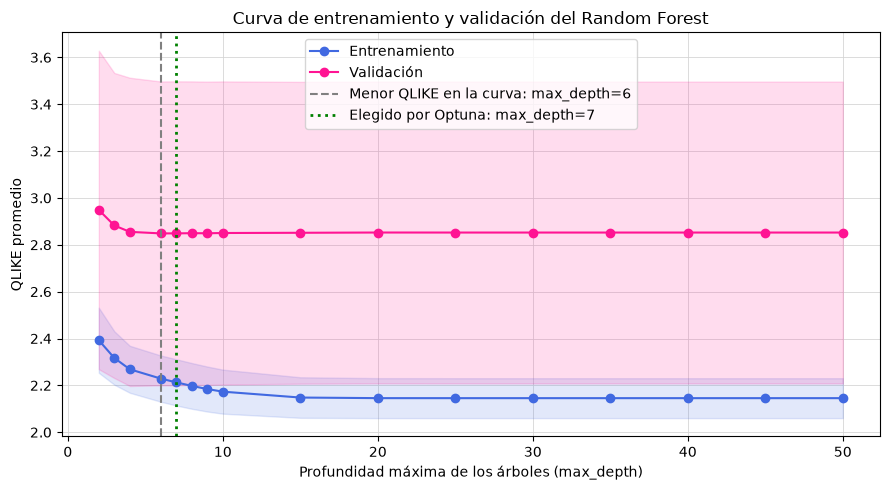

In [15]:


plt.style.use("default")
fig, ax = plt.subplots(figsize=(9, 5))


ax.plot(
    resumen_md.index, resumen_md["qlike_train_mean"],
    "o-", color="royalblue", label="Entrenamiento"
)
ax.fill_between(
    resumen_md.index,
    resumen_md["qlike_train_mean"] - resumen_md["qlike_train_std"],
    resumen_md["qlike_train_mean"] + resumen_md["qlike_train_std"],
    color="royalblue", alpha=0.15
)

ax.plot(
    resumen_md.index, resumen_md["qlike_val_mean"],
    "o-", color="deeppink", label="Validación"
)
ax.fill_between(
    resumen_md.index,
    resumen_md["qlike_val_mean"] - resumen_md["qlike_val_std"],
    resumen_md["qlike_val_mean"] + resumen_md["qlike_val_std"],
    color="deeppink", alpha=0.15
)

ax.axvline(
    mejor_profundidad,
    color="gray",
    linestyle="--",
    label=f"Menor QLIKE en la curva: max_depth={mejor_profundidad}"
)

ax.axvline(
    profundidad_optuna,
    color="green",
    linestyle=":",
    linewidth=2,
    label=f"Elegido por Optuna: max_depth={profundidad_optuna}"
)

ax.set_xlabel("Profundidad máxima de los árboles (max_depth)")
ax.set_ylabel("QLIKE promedio")
ax.set_title("Curva de entrenamiento y validación del Random Forest")

ax.set_axisbelow(True)
ax.grid(
    True,
    which="major",
    axis="both",
    color="lightgray",
    linestyle="-",
    linewidth=0.7,
    alpha=0.8
)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "06_curva_train_validacion_max_depth.png", dpi=150)
plt.show()

La gráfica muestra que, con profundidades pequeñas, el Random Forest tiene QLIKE alto tanto en entrenamiento como en validación, señal de **subajuste**: los árboles aún no capturan suficiente estructura. Al aumentar `max_depth`, ambos errores disminuyen. El menor QLIKE de validación en esta curva se alcanza con `max_depth=6` (**2.8486**).

Optuna eligió `max_depth=7`, con QLIKE de **2.2128 en entrenamiento** y **2.8487 en validación**. La diferencia frente a la profundidad 6 es mínima: el QLIKE de validación aumenta solo **0.0001**, por lo que ambos valores representan un desempeño prácticamente equivalente. Optuna seleccionó 7 porque optimizó el promedio de validación en su búsqueda —que puede diferir ligeramente de esta curva por el procedimiento de evaluación— y ese ensayo obtuvo el mejor resultado entre los evaluados.

A partir de `max_depth=20`, los QLIKE de entrenamiento y validación se mantienen prácticamente constantes, alrededor de **2.1454** y **2.8523**, respectivamente. Esto sugiere que los árboles más profundos ajustan mejor los datos de entrenamiento, pero ya no mejoran la capacidad de generalización. Desde esa profundidad, aumentarla no produce cambios relevantes en el desempeño: el error de entrenamiento deja de bajar y el de validación no mejora ni empeora de forma marcada. Aunque existe una brecha entre ambos, la gráfica no muestra que esta aumente con la profundidad ni que el error de validación empeore; por ello, no se observa un sobreajuste progresivo al seguir aumentando `max_depth`.

#### Número de árboles

Con los demás hiperparámetros fijos en los mejores valores, se varía `n_estimators` y se calcula la QLIKE en entrenamiento y validación (folds de la repetición 1). Árboles poco profundos con error alto en ambos indican **subajuste**; si al aumentar la profundidad el error de entrenamiento sigue bajando pero el de validación no mejora, hay **sobreajuste**.

In [16]:
parametro = "n_estimators"
valores = [100, 150, 200, 250, 300, 350, 400, 500, 600]

filas = []

for n_arboles in valores:
    params = {**best, "n_estimators": n_arboles}

    for i, (rep, fold, tr, va) in enumerate(CV):
        pipe = rf.crear_pipeline(
            K_FINAL,
            score_func=rf.puntajes_fijos(MI_FOLD[i]),
            **params
        )
        pipe.fit(X.iloc[tr], y.iloc[tr])

        pred_train = pipe.predict(X.iloc[tr])
        pred_val = pipe.predict(X.iloc[va])

        filas.append({
            "n_estimators": n_arboles,
            "rep": rep,
            "fold": fold,
            "qlike_train": rf.perdidas(y.iloc[tr], pred_train)["qlike"].mean(),
            "qlike_val": rf.perdidas(y.iloc[va], pred_val)["qlike"].mean(),
        })

curva_n = pd.DataFrame(filas)

resumen_n = curva_n.groupby("n_estimators").agg(
    qlike_train_mean=("qlike_train", "mean"),
    qlike_train_std=("qlike_train", "std"),
    qlike_val_mean=("qlike_val", "mean"),
    qlike_val_std=("qlike_val", "std"),
)

display(resumen_n.round(4))

,qlike_train_mean,qlike_train_std,qlike_val_mean,qlike_val_std
n_estimators,,,,
100,2.2127,0.0988,2.8488,0.6487
150,2.2131,0.0989,2.8510,0.6519
200,2.2130,0.0990,2.8497,0.6496
250,2.2129,0.0990,2.8492,0.6492
300,2.2129,0.0989,2.8484,0.6480
350,2.2128,0.0987,2.8487,0.6490
400,2.2128,0.0987,2.8492,0.6492
500,2.2128,0.0986,2.8492,0.6492
600,2.2129,0.0986,2.8497,0.6499


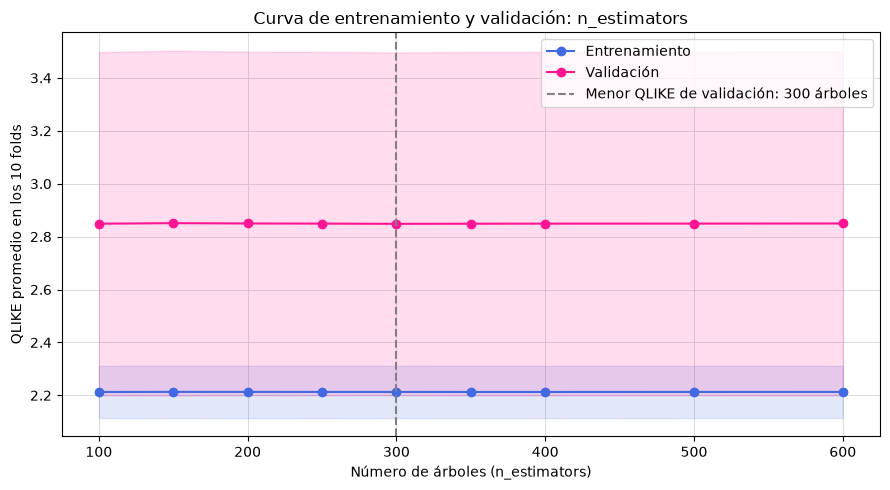

In [17]:
mejor_n = resumen_n["qlike_val_mean"].idxmin()

fig, ax = plt.subplots(figsize=(9, 5))
plt.style.use("default")

ax.plot(
    resumen_n.index, resumen_n["qlike_train_mean"],
    "o-", color="royalblue", label="Entrenamiento"
)
ax.fill_between(
    resumen_n.index,
    resumen_n["qlike_train_mean"] - resumen_n["qlike_train_std"],
    resumen_n["qlike_train_mean"] + resumen_n["qlike_train_std"],
    color="royalblue", alpha=0.15
)

ax.plot(
    resumen_n.index, resumen_n["qlike_val_mean"],
    "o-", color="deeppink", label="Validación"
)
ax.fill_between(
    resumen_n.index,
    resumen_n["qlike_val_mean"] - resumen_n["qlike_val_std"],
    resumen_n["qlike_val_mean"] + resumen_n["qlike_val_std"],
    color="deeppink", alpha=0.15
)

ax.axvline(
    mejor_n, color="gray", linestyle="--",
    label=f"Menor QLIKE de validación: {mejor_n} árboles"
)

ax.set_xlabel("Número de árboles (n_estimators)")
ax.set_ylabel("QLIKE promedio en los 10 folds")
ax.set_title("Curva de entrenamiento y validación: n_estimators")

ax.set_axisbelow(True)
ax.grid(
    True,
    which="major",
    axis="both",
    color="lightgray",
    linestyle="-",
    linewidth=0.7,
    alpha=0.8
)
ax.legend()
plt.tight_layout()
plt.show()

La gráfica muestra que, entre 100 y 600 árboles, los QLIKE de entrenamiento y validación se mantienen prácticamente constantes: alrededor de **2.21** y **2.85**, respectivamente. El menor QLIKE de validación se alcanza con `n_estimators=300`, aunque la diferencia respecto a los demás valores es imperceptible en la gráfica. Optuna eligió `n_estimators=350`.

Esto sugiere que, dentro del rango evaluado, aumentar el número de árboles no produce cambios relevantes en el desempeño ni mejora la capacidad de generalización. La brecha entre entrenamiento y validación persiste, pero como ambas curvas permanecen estables, la gráfica no muestra un sobreajuste progresivo asociado al aumento de `n_estimators`.

#### Número de días por hoja

In [18]:
valores_leaf = [5, 10, 20, 40, 80, 120, 160, 200, 250, 300]

filas_leaf = []

for min_leaf in valores_leaf:
    params = {**best, "min_samples_leaf": min_leaf}

    for i, (rep, fold, tr, va) in enumerate(CV):
        pipe = rf.crear_pipeline(
            K_FINAL,
            score_func=rf.puntajes_fijos(MI_FOLD[i]),
            **params
        )
        pipe.fit(X.iloc[tr], y.iloc[tr])

        pred_train = pipe.predict(X.iloc[tr])
        pred_val = pipe.predict(X.iloc[va])

        filas_leaf.append({
            "min_samples_leaf": min_leaf,
            "rep": rep,
            "fold": fold,
            "qlike_train": rf.perdidas(y.iloc[tr], pred_train)["qlike"].mean(),
            "qlike_val": rf.perdidas(y.iloc[va], pred_val)["qlike"].mean(),
        })

curva_leaf = pd.DataFrame(filas_leaf)

resumen_leaf = curva_leaf.groupby("min_samples_leaf").agg(
    qlike_train_mean=("qlike_train", "mean"),
    qlike_train_std=("qlike_train", "std"),
    qlike_val_mean=("qlike_val", "mean"),
    qlike_val_std=("qlike_val", "std"),
)

display(resumen_leaf.round(4))

,qlike_train_mean,qlike_train_std,qlike_val_mean,qlike_val_std
min_samples_leaf,,,,
5,2.2084,0.1002,2.8747,0.6955
10,2.2128,0.0987,2.8487,0.6490
20,2.2174,0.0949,2.8696,0.6837
40,2.2290,0.0907,2.9225,0.7734
80,2.2541,0.0907,2.9958,0.9040
120,2.2764,0.0943,3.0850,1.0548
160,2.2917,0.0981,3.1128,1.0986
200,2.3046,0.1022,3.1314,1.1198
250,2.3208,0.1049,3.1820,1.1973


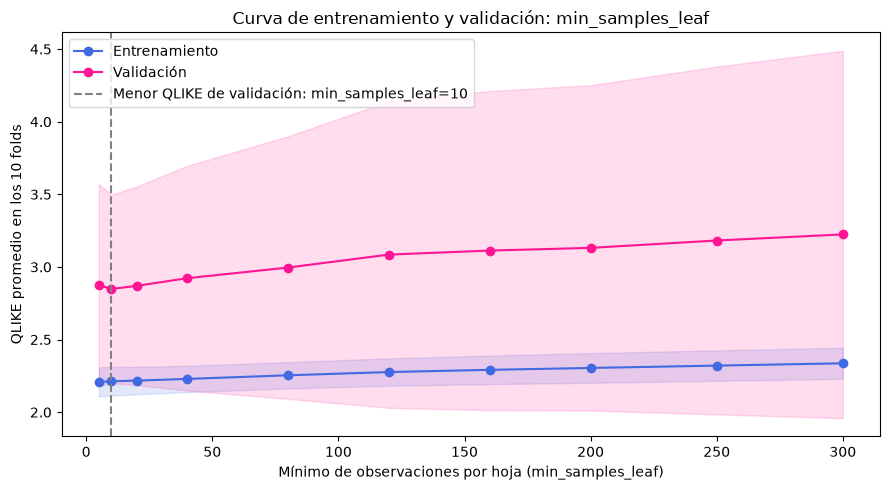

In [19]:
mejor_leaf = resumen_leaf["qlike_val_mean"].idxmin()

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    resumen_leaf.index, resumen_leaf["qlike_train_mean"],
    "o-", color="royalblue", label="Entrenamiento"
)
ax.fill_between(
    resumen_leaf.index,
    resumen_leaf["qlike_train_mean"] - resumen_leaf["qlike_train_std"],
    resumen_leaf["qlike_train_mean"] + resumen_leaf["qlike_train_std"],
    color="royalblue", alpha=0.15
)

ax.plot(
    resumen_leaf.index, resumen_leaf["qlike_val_mean"],
    "o-", color="deeppink", label="Validación"
)
ax.fill_between(
    resumen_leaf.index,
    resumen_leaf["qlike_val_mean"] - resumen_leaf["qlike_val_std"],
    resumen_leaf["qlike_val_mean"] + resumen_leaf["qlike_val_std"],
    color="deeppink", alpha=0.15
)

ax.axvline(
    mejor_leaf, color="gray", linestyle="--",
    label=f"Menor QLIKE de validación: min_samples_leaf={mejor_leaf}"
)

ax.set_xlabel("Mínimo de observaciones por hoja (min_samples_leaf)")
ax.set_ylabel("QLIKE promedio en los 10 folds")
ax.set_title("Curva de entrenamiento y validación: min_samples_leaf")
ax.legend()
plt.tight_layout()
plt.show()

Al aumentar `min_samples_leaf`, el QLIKE de entrenamiento y el de validación suben, aunque el incremento es más pronunciado en validación. Esto sugiere que exigir más observaciones por hoja vuelve los árboles demasiado restrictivos y reduce su capacidad de ajuste, un patrón compatible con subajuste. El menor QLIKE de validación entre los valores evaluados se obtiene con `min_samples_leaf=10` (elegido por Optuna); a partir de ese punto, aumentar el tamaño mínimo de las hojas no mejora la generalización y se asocia con un desempeño de validación menos favorable.

**Conclusión**:  Las curvas muestran que la complejidad del Random Forest está controlada principalmente por  min_samples_leaf.

- `max_depth`: con árboles poco profundos (2–4) el error de validación es mayor, señal de subajuste. La QLIKE de validación alcanza su mínimo cerca de max_depth = 6 (≈ 2,85) y luego se mantiene estable, mientras el error de entrenamiento sigue bajando hasta una profundidad de ~15. La brecha creciente indica una tendencia al sobreajuste en profundidades mayores, aunque sin deterioro del error de validación. Optuna seleccionó max_depth = 7, prácticamente equivalente al mínimo.
- `min_samples_leaf`: al aumentar el número mínimo de observaciones por hoja, tanto el error de entrenamiento (de 2,21 a 2,34) como el de validación (de 2,85 a 3,23) aumentan. Hojas grandes simplifican demasiado los árboles y producen subajuste; el menor error de validación se obtiene con min_samples_leaf = 10, el valor elegido por Optuna.
- `n_estimators`: ambas curvas son planas entre 100 y 600 árboles. Es lo esperado en un Random Forest: agregar árboles reduce la varianza del promedio pero no aumenta el sobreajuste.

En conjunto, Optuna seleccionó hiperparámetros ubicados en la zona de menor error de validación, sin entrar en la región de sobreajuste. Las diferencias frente a configuraciones más simples, como max_depth = 6 o 100 árboles, son despreciables (≈ 0,001 en QLIKE). Esto indica que el desempeño es estable alrededor de la configuración elegida y que una versión más simple del modelo tendría un rendimiento prácticamente igual.

Las bandas sombreadas de validación son amplias en todas las curvas. Esa variabilidad se debe a las diferencias entre los periodos de validación (en especial 2020), no a los hiperparámetros, y es mucho mayor que el efecto de cualquiera de ellos.

In [20]:
curvas_hiperparametros = pd.concat(
    [
        resumen_md.rename_axis("valor").reset_index().assign(hiperparametro="max_depth"),
        resumen_n.rename_axis("valor").reset_index().assign(hiperparametro="n_estimators"),
        resumen_leaf.rename_axis("valor").reset_index().assign(hiperparametro="min_samples_leaf"),
    ],
    ignore_index=True
)

curvas_hiperparametros = curvas_hiperparametros[
    [
        "hiperparametro",
        "valor",
        "qlike_train_mean",
        "qlike_train_std",
        "qlike_val_mean",
        "qlike_val_std",
    ]
].sort_values(["hiperparametro", "valor"]).reset_index(drop=True)

display(curvas_hiperparametros.round(4))

,hiperparametro,valor,qlike_train_mean,qlike_train_std,qlike_val_mean,qlike_val_std
0,max_depth,2,2.3925,0.1389,2.9487,0.6797
1,max_depth,3,2.3168,0.1139,2.8824,0.6511
2,max_depth,4,2.2686,0.1003,2.8552,0.6578
3,max_depth,6,2.2288,0.0987,2.8486,0.6485
4,max_depth,7,2.2128,0.0987,2.8487,0.6490
5,max_depth,8,2.1976,0.0976,2.8496,0.6479
6,max_depth,9,2.1842,0.0960,2.8492,0.6472
7,max_depth,10,2.1731,0.0940,2.8503,0.6470
8,max_depth,15,2.1480,0.0865,2.8513,0.6442
9,max_depth,20,2.1455,0.0853,2.8524,0.6441


### Historial

C:\Users\ASUS\AppData\Local\Temp\ipykernel_33080\2557148973.py:1: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(study)


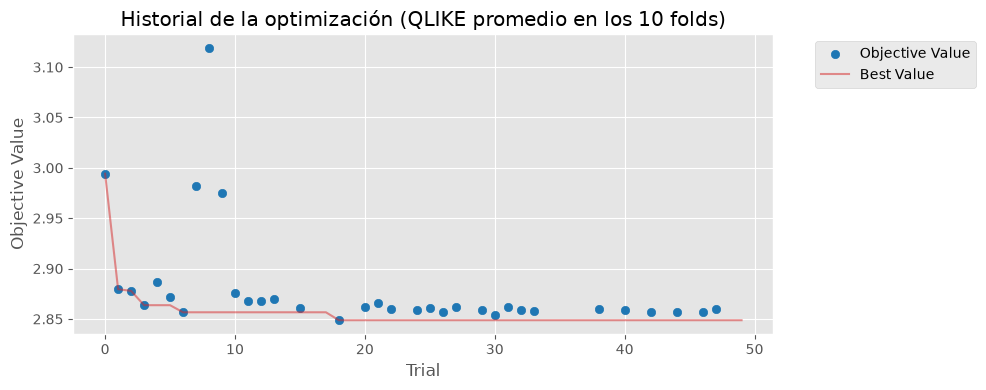

In [21]:
ax = plot_optimization_history(study)
ax.set_title("Historial de la optimización (QLIKE promedio en los 10 folds)")
plt.gcf().set_size_inches(10, 4); plt.tight_layout()
plt.savefig(FIG_DIR / "06_optuna_historial.png", dpi=150); plt.show()

La gráfica muestra cómo evolucionó la búsqueda de Optuna a través de los ensayos. En el eje horizontal aparece el número de ensayo y en el vertical, su QLIKE promedio de validación en los 10 folds; como se busca minimizar el QLIKE, los valores más bajos son mejores. Los puntos azules representan el resultado de cada ensayo y la línea roja muestra el mejor resultado alcanzado hasta ese momento.

Al principio hay más variación entre los resultados, incluidos algunos QLIKE cercanos o superiores a 3.0. A medida que avanzan los ensayos, los valores se concentran alrededor de **2.85**. La línea roja baja hasta aproximadamente **2.8487** y luego permanece estable, lo que indica que los ensayos posteriores no encontraron una mejora apreciable. Así, Optuna identificó pronto una región competitiva y después exploró combinaciones con resultados similares, aunque no mejores.

### Importancia de Hiperparámetros

C:\Users\ASUS\AppData\Local\Temp\ipykernel_33080\1957757051.py:1: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_param_importances(study)


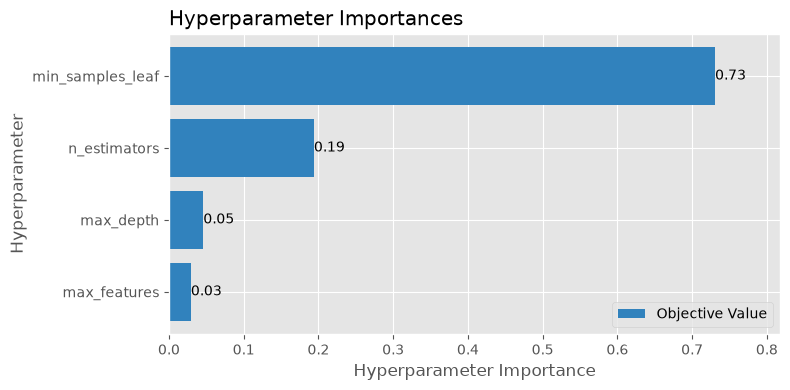

In [22]:
ax = plot_param_importances(study)
plt.gcf().set_size_inches(8, 4); plt.tight_layout()
plt.savefig(FIG_DIR / "06_optuna_importancia_hiperparametros.png", dpi=150); plt.show()


La importancia de hiperparámetros estimada por Optuna indica que **`min_samples_leaf` fue el que más influyó en las diferencias de QLIKE entre los ensayos** (0.73). Le sigue `n_estimators` (0.19), mientras que `max_depth` (0.05) y `max_features` (0.03) tuvieron menor influencia en esta búsqueda.

Esto sugiere que el tamaño mínimo de las hojas fue el factor más decisivo para distinguir el desempeño de las combinaciones probadas. La gráfica refleja la importancia relativa dentro de los ensayos realizados: no indica que ese hiperparámetro explique el 73 % del QLIKE ni garantiza que conserve la misma importancia fuera de esta búsqueda.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_33080\138215810.py:1: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  axes = plot_slice(study, params=["n_estimators", "max_depth", "min_samples_leaf", "max_features"])
C:\Users\ASUS\AppData\Local\Temp\ipykernel_33080\138215810.py:2: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.gcf().set_size_inches(16, 4); plt.tight_layout()


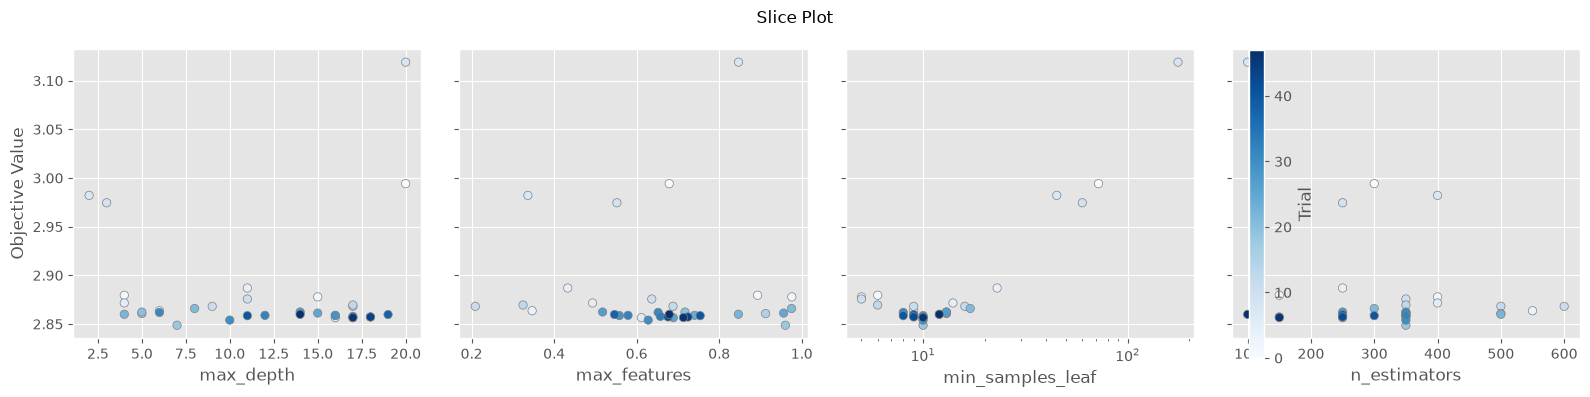

In [23]:
axes = plot_slice(study, params=["n_estimators", "max_depth", "min_samples_leaf", "max_features"])
plt.gcf().set_size_inches(16, 4); plt.tight_layout()
plt.savefig(FIG_DIR / "06_optuna_slice.png", dpi=150); plt.show()

El *slice plot* muestra cómo se distribuyen los resultados de los ensayos según el valor de cada hiperparámetro. Cada punto representa un ensayo; cuanto menor es su valor objetivo (QLIKE), mejor fue su resultado. El color indica el orden del ensayo.

- **`max_depth`**: los mejores QLIKE se agrupan cerca de 2.85 en varias profundidades. No se aprecia una relación marcada entre mayor profundidad y mejor resultado.
- **`max_features`**: la mayoría de los mejores ensayos se concentran aproximadamente entre 0.6 y 0.8, aunque hay resultados similares en otros valores.
- **`min_samples_leaf`**: los mejores resultados se agrupan cerca de valores bajos, alrededor de 10. Los valores más altos tienden a mostrar QLIKE algo mayor.
- **`n_estimators`**: los mejores resultados aparecen con distintos números de árboles, sin una tendencia clara que indique que más árboles mejoren el QLIKE.

En conjunto, la gráfica sugiere que `min_samples_leaf` distingue con mayor claridad los resultados dentro de los valores explorados, mientras que para los demás hiperparámetros no se observa una tendencia fuerte. Estas asociaciones describen los ensayos realizados y no prueban por sí solas el efecto de cada hiperparámetro de forma aislada, ya que Optuna varió varias combinaciones.

### Curvas de aprendizaje

,n_train,train,train_sd,val,val_sd
0,500,2.6038,0.3201,3.1968,1.2609
1,1000,2.5199,0.2442,2.8855,0.6401
2,1500,2.4311,0.1731,2.8575,0.6567
3,2000,2.3366,0.2247,2.8555,0.6574
4,2300,2.2827,0.1893,2.8528,0.6517


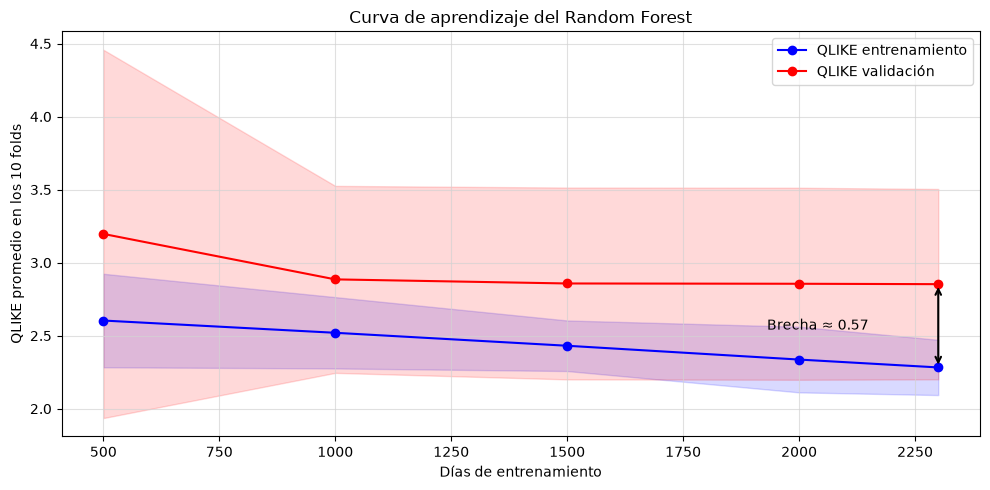

In [24]:
# Tamaños de entrenamiento a comparar
TAMANOS_TRAIN = [500, 1000, 1500, 2000, 2300]

filas = []

# Evaluar cada tamaño en todos los folds
for n in TAMANOS_TRAIN:
    for i, (rep, fold, tr, va) in enumerate(CV):
        # Tomar los n días más recientes del entrenamiento del fold
        tr_sub = tr[-n:]

        # El selector calcula la información mutua solo con este subconjunto
        pipe = rf.crear_pipeline(K_FINAL, **best)
        pipe.fit(X.iloc[tr_sub], y.iloc[tr_sub])

        pred_train = pipe.predict(X.iloc[tr_sub])
        pred_val = pipe.predict(X.iloc[va])

        qlike_train = rf.perdidas(
            y.iloc[tr_sub], pred_train
        )["qlike"].mean()

        qlike_val = rf.perdidas(
            y.iloc[va], pred_val
        )["qlike"].mean()

        filas.append({
            "n_train": n,
            "rep": rep,
            "fold": fold,
            "train": qlike_train,
            "validación": qlike_val,
        })

# Resumir las métricas de los 10 folds para cada tamaño de entrenamiento
resumen_apr = (
    pd.DataFrame(filas)
    .groupby("n_train")
    .agg(
        train=("train", "mean"),
        train_sd=("train", "std"),
        val=("validación", "mean"),
        val_sd=("validación", "std"),
    )
    .reset_index()
)

display(resumen_apr.round(4))

# Graficar la curva de aprendizaje
plt.style.use("default")
fig, ax = plt.subplots(figsize=(10, 5))

x = resumen_apr["n_train"].to_numpy()
train = resumen_apr["train"].to_numpy()
train_sd = resumen_apr["train_sd"].to_numpy()
val = resumen_apr["val"].to_numpy()
val_sd = resumen_apr["val_sd"].to_numpy()

ax.plot(x, train, "o-", color="blue", label="QLIKE entrenamiento")
ax.fill_between(
    x, train - train_sd, train + train_sd,
    color="blue", alpha=0.15
)

ax.plot(x, val, "o-", color="red", label="QLIKE validación")
ax.fill_between(
    x, val - val_sd, val + val_sd,
    color="red", alpha=0.15
)

# Marcar la brecha entre entrenamiento y validación en el tamaño máximo
x_final = x[-1]
train_final = train[-1]
val_final = val[-1]

ax.annotate(
    "",
    xy=(x_final, val_final),
    xytext=(x_final, train_final),
    arrowprops=dict(arrowstyle="<->", color="black", linewidth=1.5),
)
ax.text(
    x_final - 150,
    (train_final + val_final) / 2,
    f"Brecha ≈ {val_final - train_final:.2f}",
    ha="right",
    va="center",
)

ax.set_xlabel("Días de entrenamiento")
ax.set_ylabel("QLIKE promedio en los 10 folds")
ax.set_title("Curva de aprendizaje del Random Forest")
ax.grid(True, color="lightgray", alpha=0.7)
ax.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "06_curva_aprendizaje_tamanos_fijos.png", dpi=150)
plt.show()

La curva muestra que, al aumentar el entrenamiento de **500 a 1.000 días**, el QLIKE de validación baja de aproximadamente **3,20 a 2,89**, señal de una mejora inicial. Con más datos, la validación se estabiliza cerca de **2,86**; por tanto, añadir observaciones por encima de 1.000 días aporta poca mejora promedio en los folds evaluados.

El QLIKE de entrenamiento disminuye gradualmente, de aproximadamente **2,60 a 2,29**, mientras el de validación permanece más alto. En el último tamaño evaluado, la brecha es de unos **0,57**. Esto indica una diferencia entre el ajuste en entrenamiento y el desempeño en datos no vistos, aunque por sí sola no demuestra sobreajuste: también puede reflejar que los periodos de validación tienen distinta dificultad.

Las bandas sombreadas representan la variabilidad entre los 10 folds y son especialmente amplias para validación. Esto sugiere que el desempeño cambia bastante según el periodo; por ello, conviene interpretar el promedio junto con los resultados individuales de cada fold.

## 6. Errores del modelo final por fold

Con los mejores hiperparámetros, en cada uno de los 10 folds:
1. `pipeline.fit(X_train, y_train)`: la información mutua se calcula con el entrenamiento del fold, se eligen sus 16 mejores variables y se entrena el Random Forest.
2. `pipeline.predict(X_train)`: error de **entrenamiento** (dentro de muestra).
3. `pipeline.predict(X_val)`: error de **validación**, en días que el modelo no vio.

Los pronósticos se indexan por el día objetivo τ, igual que los del EGARCH, para compararlos en los mismos días. Una brecha positiva entre validación y entrenamiento es esperable en un Random Forest; una brecha muy grande indicaría sobreajuste.

In [25]:
filas, pron, importancias = [], [], []

for rep, fold, tr, va in CV:
    f = FOLDS[(FOLDS["rep"] == rep) & (FOLDS["fold"] == fold)].iloc[0]

    pipe = rf.crear_pipeline(K_FINAL, **best)               # pipeline completo con información mutua real
    pipe.fit(X.iloc[tr], y.iloc[tr])                     # ajuste solo con el entrenamiento

    h_tr = pipe.predict(X.iloc[tr])                      # error dentro de muestra
    h_va = np.clip(pipe.predict(X.iloc[va]), rf.H_MIN, None)  # pronóstico de validación
    L_tr, L_va = rf.perdidas(y.iloc[tr], h_tr), rf.perdidas(y.iloc[va], h_va)

    filas.append({"rep": rep, "fold": fold, "val_ini": f.val_ini.date(), "val_fin": f.val_fin.date(),
                  "n": len(va),
                  "mse_rf": L_va["mse"].mean(), "qlike_rf": L_va["qlike"].mean(),
                  "mse_train": L_tr["mse"].mean(), "qlike_train": L_tr["qlike"].mean()})
    pron.append(pd.DataFrame({"y": y.iloc[va].values, "h_rf": h_va, "rep": rep, "fold": fold},
                             index=X.index[va]))

    vars_sel = X.columns[pipe.named_steps["seleccion"].get_support()]
    importancias.append(pd.Series(pipe.named_steps["modelo"].feature_importances_,
                                  index=vars_sel, name=f"R{rep}·F{fold}"))
    print(f"R{rep}·F{fold}: QLIKE train = {L_tr['qlike'].mean():.4f} | validación = {L_va['qlike'].mean():.4f}")

res_rf = pd.DataFrame(filas)
res_rf["brecha_qlike"] = res_rf["qlike_rf"] - res_rf["qlike_train"]
pron_rf = pd.concat(pron); pron_rf.index.name = "Date"
imp = pd.concat(importancias, axis=1).fillna(0)

display(res_rf.round(4))
display(res_rf[["qlike_train", "qlike_rf", "mse_train", "mse_rf"]].agg(["mean", "std"]).round(4))

R1·F1: QLIKE train = 2.0543 | validación = 3.9612


R1·F2: QLIKE train = 2.2048 | validación = 2.5321


R1·F3: QLIKE train = 2.2285 | validación = 3.1929


R1·F4: QLIKE train = 2.3032 | validación = 2.4509


R1·F5: QLIKE train = 2.3137 | validación = 2.0767


R2·F1: QLIKE train = 2.0418 | validación = 3.7994


... (2 outputs left out)

R2·F4: QLIKE train = 2.2695 | validación = 2.8952


R2·F5: QLIKE train = 2.3158 | validación = 2.0965


,rep,fold,val_ini,val_fin,n,mse_rf,qlike_rf,mse_train,qlike_train,brecha_qlike
0,1,1,2020-01-01,2020-12-31,251,6273.1761,3.9612,11.4481,2.0543,1.9069
1,1,2,2021-01-01,2021-12-31,252,107.8630,2.5321,320.5389,2.2048,0.3272
2,1,3,2022-01-01,2022-12-31,251,206.2362,3.1929,299.1688,2.2285,0.9644
3,1,4,2023-01-01,2023-12-31,250,15.4085,2.4509,287.2366,2.3032,0.1477
4,1,5,2024-01-01,2024-12-31,252,6.5271,2.0767,267.2817,2.3137,-0.2370
5,2,1,2019-07-01,2020-06-30,251,6269.4160,3.7994,11.3243,2.0418,1.7575
6,2,2,2020-07-01,2021-06-30,252,29.7900,2.5346,334.9815,2.1836,0.3510
7,2,3,2021-07-01,2022-06-30,252,273.6881,2.9481,307.1701,2.2124,0.7356
8,2,4,2022-07-01,2023-06-30,251,56.7975,2.8952,295.2645,2.2695,0.6256
9,2,5,2023-07-01,2024-06-30,250,5.2369,2.0965,276.3791,2.3158,-0.2193


,qlike_train,qlike_rf,mse_train,mse_rf
mean,2.2128,2.8487,241.0794,1324.4140
std,0.0987,0.6490,122.6517,2608.7691


En promedio, el QLIKE fue aproximadamente 2,21 en entrenamiento y 2,85 en validación. Como un QLIKE menor indica mejor desempeño, la diferencia media de alrededor de 0,64 muestra que el modelo rinde peor en datos no vistos. Sin embargo, la brecha cambia bastante entre folds, así que no apunta a un sobreajuste uniforme.

Las validaciones de 2020 presentan los errores más altos (QLIKE de 3,80–3,96), y las que abarcan 2022 también muestran errores elevados (2,95–3,19). Esto sugiere que el desempeño depende del periodo y que el modelo tuvo más dificultad en esos tramos. En cambio, en los folds que validan principalmente 2024, el QLIKE de validación es menor que el de entrenamiento; por tanto, la brecha no es siempre positiva.

Las brechas positivas más altas aparecen en los folds cuya validación incluye 2020:
- R1·F1: brecha 1,9069; validación del 2 de enero al 31 de diciembre de 2020.
- R2·F1: brecha 1,7575; validación del 1 de julio de 2019 al 30 de junio de 2020.

También destaca R1·F3, con brecha 0,9644, cuya validación va del 3 de enero al 30 de diciembre de 2022. Estos resultados indican que la diferencia entre entrenamiento y validación depende bastante del periodo evaluado.


En conjunto, los resultados muestran variabilidad temporal y una brecha promedio entre entrenamiento y validación, pero no bastan para atribuirla únicamente al sobreajuste. El QLIKE alto en algunos periodos también puede reflejar cambios en el comportamiento de la volatilidad del WTI.

## 7. Gráficas de resultados

- QLIKE y MSE de entrenamiento y validación por fold.
- Importancia media de las variables en el Random Forest (una variable no elegida en un fold cuenta como 0).
- Pronóstico del Random Forest frente al Parkinson observado en dos periodos de validación.

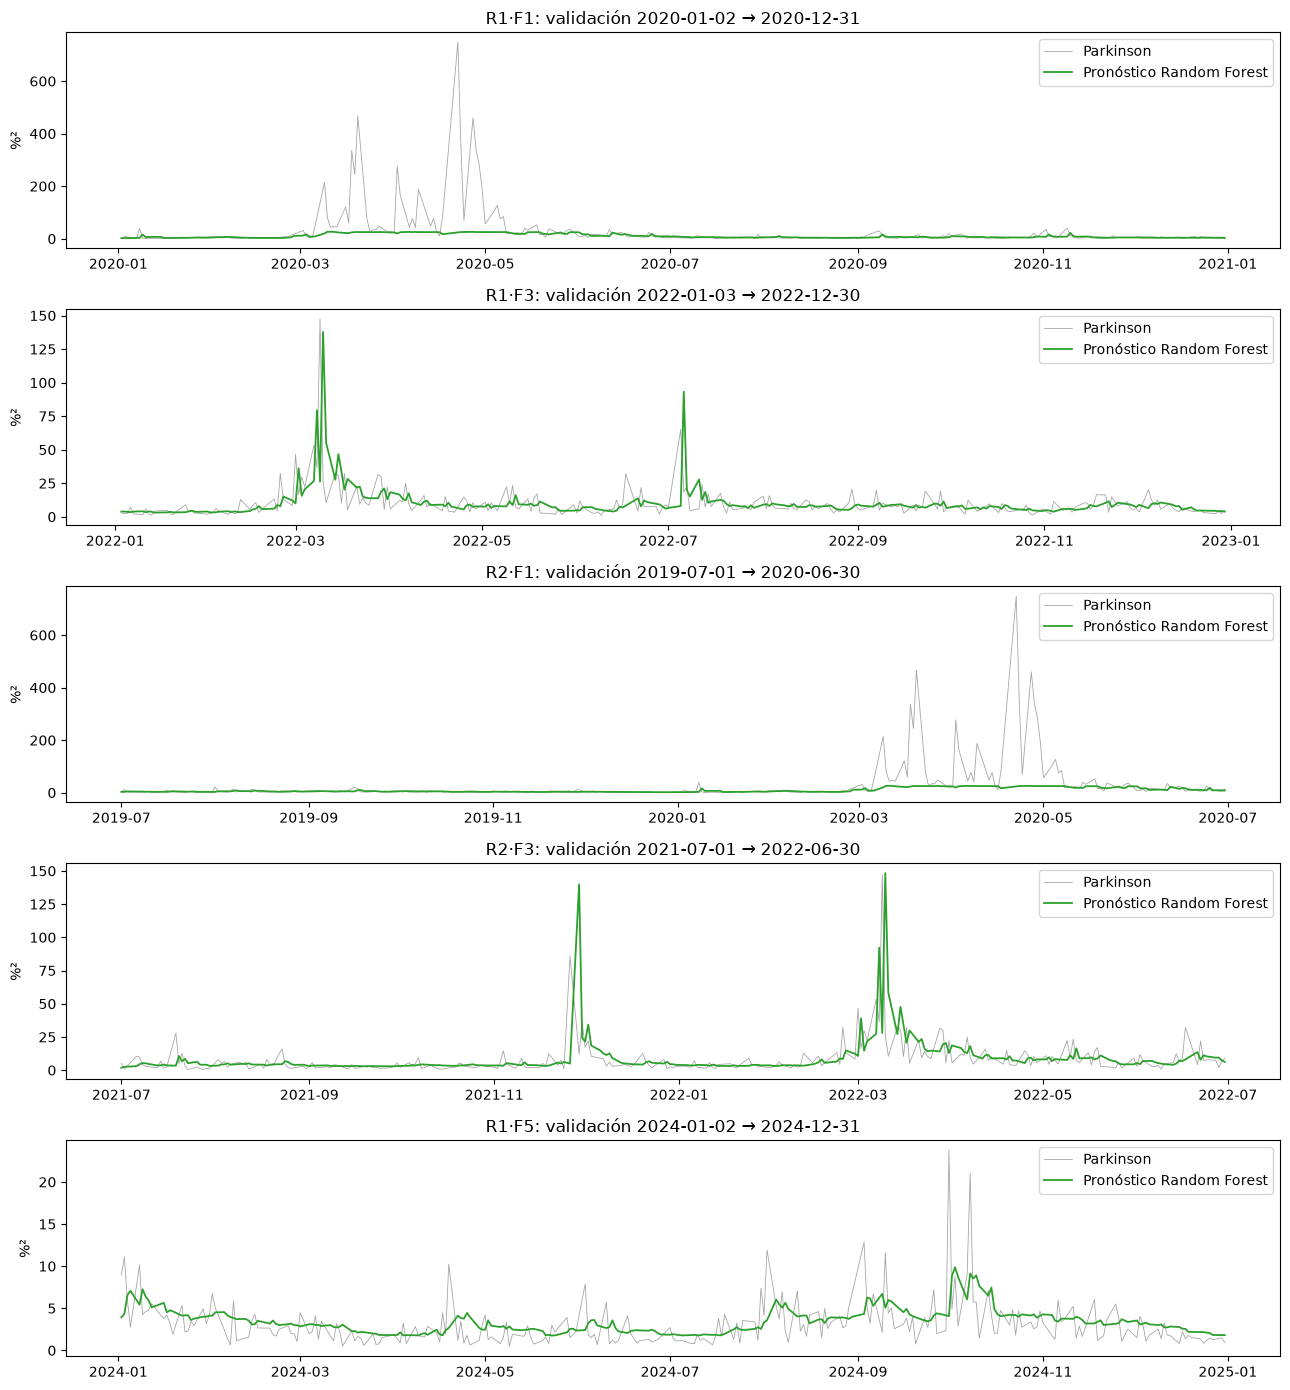

In [26]:

folds_graf = [(1, 1), (1, 3), (2, 1), (2, 3), (1, 5)]

fig, axes = plt.subplots(len(folds_graf), 1, figsize=(13, 14))

for ax, (rep, fold) in zip(axes, folds_graf):
    d = pron_rf.query("rep == @rep and fold == @fold")

    ax.plot(
        d.index, d["y"],
        lw=0.6, color="grey", alpha=0.7, label="Parkinson"
    )
    ax.plot(
        d.index, d["h_rf"],
        lw=1.3, color="tab:green", label="Pronóstico Random Forest"
    )

    ax.set_title(
        f"R{rep}·F{fold}: validación "
        f"{d.index.min().date()} → {d.index.max().date()}"
    )
    ax.set_ylabel("%²")
    ax.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "06_pronosticos_folds.png", dpi=150)
plt.show()


La gráfica compara la varianza diaria estimada por Parkinson (gris) con el pronóstico del Random Forest (verde), en unidades de \(\%²\). En conjunto, el modelo sigue mejor los niveles y cambios moderados que los picos repentinos.

- **R1·F1, 2020:** los picos extremos de marzo a mayo, con valores de Parkinson superiores a 700, son muy difíciles de anticipar. El Random Forest genera pronósticos mucho menores, lo que refleja una fuerte subestimación de esos eventos y ayuda a explicar el QLIKE alto del fold.
- **R2·F1, julio de 2019–junio de 2020:** se observa el mismo problema durante los picos de marzo a mayo de 2020. Antes de ese episodio, ambas series se mantienen en niveles bajos y relativamente cercanos.
- **R1·F3, 2022:** el pronóstico responde a varios cambios pronunciados, como el pico de marzo, aunque no siempre reproduce exactamente la magnitud; en julio, por ejemplo, el pronóstico supera el valor observado.
- **R2·F3, julio de 2021–junio de 2022:** el modelo recoge algunos episodios de alta volatilidad, pero en ciertos picos se desvía del valor observado y luego suaviza la variación.
- **R1·F5, 2024:** el pronóstico sigue razonablemente el nivel y la evolución general, pero suaviza algunos picos puntuales, como los observados hacia septiembre y octubre.

En síntesis, los episodios extremos de 2020 son los más difíciles para el modelo, mientras que en periodos menos abruptos el pronóstico suele seguir mejor la dinámica general. Como las variables predictoras contienen información hasta el día anterior, el Random Forest no dispone de información para anticipar un salto inesperado del mismo día; por eso, estos resultados reflejan también la dificultad propia de pronosticar eventos repentinos.

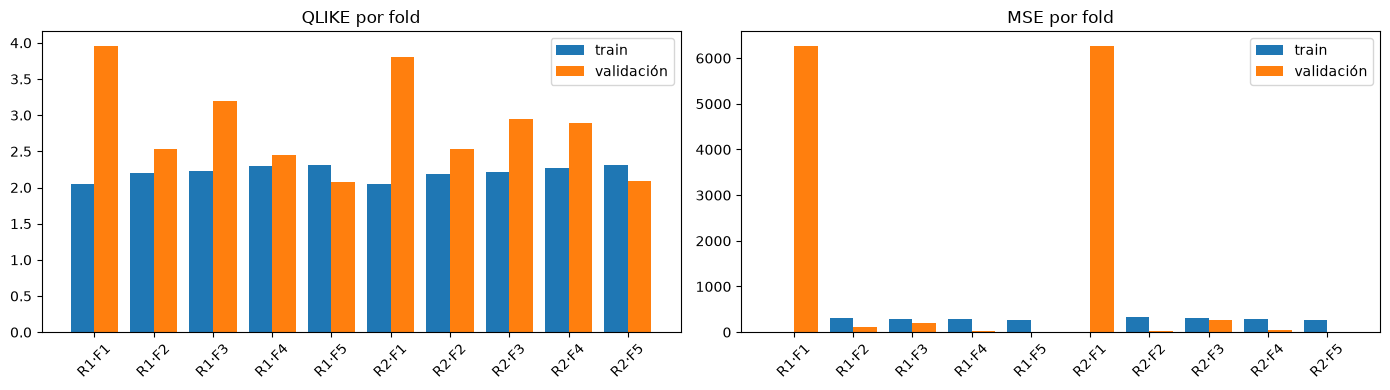

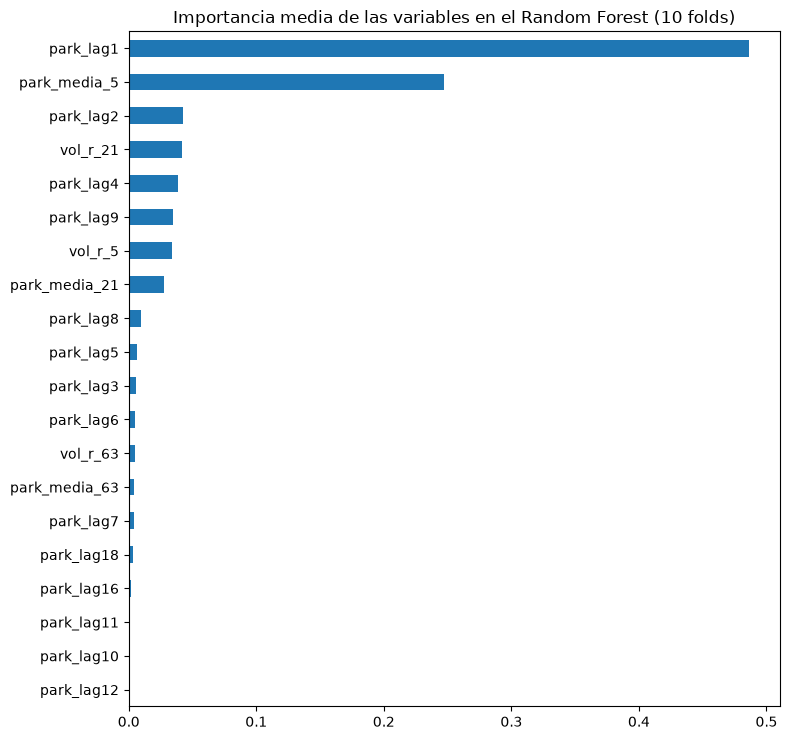

In [27]:
etiq = [f"R{a}·F{b}" for a, b in zip(res_rf["rep"], res_rf["fold"])]
x = np.arange(len(etiq))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, met in zip(ax, ["qlike", "mse"]):
    col_val = f"{met}_rf"
    a.bar(x - 0.2, res_rf[f"{met}_train"], 0.4, label="train")
    a.bar(x + 0.2, res_rf[col_val], 0.4, label="validación")
    a.set_xticks(x, etiq, rotation=45); a.set_title(f"{met.upper()} por fold"); a.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "06_errores_por_fold.png", dpi=150); plt.show()

imp_media = imp.mean(axis=1).sort_values()
imp_media.plot.barh(figsize=(8, 0.3 * len(imp_media) + 1.5),
                    title="Importancia media de las variables en el Random Forest (10 folds)")
plt.tight_layout(); plt.savefig(FIG_DIR / "06_importancia_variables.png", dpi=150); plt.show()


El gráfico compara el desempeño en entrenamiento y validación en cada fold usando QLIKE y MSE. En ambos paneles, la validación varía entre folds: destacan **R1:F1 y R2:F1**, cuyos valores son mucho mayores que los de la mayoría de los demás folds. Esto indica que el desempeño depende del período evaluado y que esos folds presentan errores particularmente altos. En QLIKE también se observa que, en algunos folds, validación es similar o incluso menor que entrenamiento; por tanto, la diferencia entre ambos no es igual en todos los períodos.

Los valores de MSE de validación en R1:F1 y R2:F1 son muy grandes y dominan la escala del gráfico. El MSE eleva al cuadrado los errores, por lo que unos pocos errores extremos pueden influir mucho en su promedio. QLIKE también refleja el peor desempeño en esos folds, pero ofrece una evaluación relativa de errores de pronóstico de varianza y es robusto ante el uso de ciertos proxies ruidosos de volatilidad. Por eso suele ser una métrica principal para comparar pronósticos de volatilidad; MSE puede servir como complemento.

QLIKE y MSE son funciones de pérdida, y sus magnitudes no se comparan directamente porque tienen escalas y penalizaciones distintas. Más bien, permite ver que ambos criterios identifican folds con errores elevados, aunque MSE hace que los valores extremos resalten mucho más.

Ahora, con respecto a la importancia de las variables, `park_lag1`, que corresponde al estimador de Parkinson del día anterior, es la más relevante para el Random Forest, con una importancia media cercana a **0.49** en los 10 folds. Le sigue `park_media_5`, el promedio del estimador de Parkinson en los últimos cinco días, con aproximadamente **0.25**. El resto de las variables tiene una importancia bastante menor; entre ellas destacan `park_lag2`, `vol_r_21` y `park_lag4`.

En conjunto, el gráfico sugiere que las predicciones dependen principalmente de la información reciente del estimador de Parkinson, en particular de su valor del día previo y de su promedio a cinco días. Las importancias corresponden a la contribución relativa estimada por el modelo; no indican por sí solas causalidad y pueden repartirse entre variables correlacionadas.

## Guardar resultados


Se guardan con el mismo formato que el modelo econométrico, para usarlos en el notebook de comparación estadística.

In [28]:
res_rf[["rep", "fold", "mse_train", "qlike_train"]].to_csv(RES_DIR / "rf_errores_train_por_fold.csv", index=False)
res_rf.to_csv(RES_DIR / "rf_errores_por_fold.csv", index=False)
pron_rf.to_csv(RES_DIR / "rf_pronosticos_diarios.csv")
imp.to_csv(RES_DIR / "rf_importancia_por_fold.csv")
curvas_hiperparametros.to_csv(RES_DIR / "rf_curvas_hiperparametros.csv")
resumen_apr.to_csv(RES_DIR / "rf_curva_aprendizaje.csv")

mejores = {"k": K_FINAL, **best,
           "qlike_validacion_optuna": float(study.best_value),
           "qlike_validacion_final": float(res_rf["qlike_rf"].mean())}
(RES_DIR / "rf_mejores_hiperparametros.json").write_text(json.dumps(mejores, indent=4), encoding="utf-8")

study.trials_dataframe().to_csv(RES_DIR / "rf_optuna_trials.csv", index=False)
joblib.dump(study, RES_DIR / "rf_optuna_study.pkl")
print("Archivos guardados en", RES_DIR)

Archivos guardados en c:\Users\ASUS\Desktop\Maestria IA USFQ\AprendizajeSupervisado\Proyectofinal_ml_wti\results


## 9. Conclusiones


1. Optuna seleccionó `n_estimators=350`, `max_depth=7`, `min_samples_leaf=10` y `max_features≈0.96`, manteniendo `k=16` variables. El mejor ensayo obtuvo un QLIKE medio de validación de **2,8487** en los 10 folds. El tamaño de hoja elegido es relativamente pequeño dentro del rango explorado (5–200), por lo que los resultados no indican que el modelo requiera un suavizado fuerte para controlar los extremos. De las 50 pruebas registradas, 31 finalizaron, 13 fueron podadas y 6 quedaron fallidas durante la depuración del código; estas últimas no contribuyeron al valor óptimo.

2. La curva de `max_depth` muestra que el QLIKE de validación mejora hasta una profundidad cercana a 6 y luego permanece prácticamente estable (≈2,85), mientras el error de entrenamiento sigue descendiendo. La diferencia entre el mínimo de la curva (`max_depth=6`, QLIKE≈2,8486) y la elección de Optuna (`max_depth=7`, QLIKE≈2,8487) es mínima. Por tanto, una mayor profundidad no aporta una mejora apreciable en validación; la brecha creciente entre entrenamiento y validación sugiere una tendencia al sobreajuste, pero no un deterioro pronunciado del QLIKE de validación.

3. La curva de aprendizaje con tamaños fijos muestra una mejora inicial: el QLIKE promedio de validación baja de **3,1968** con 500 días de entrenamiento a **2,8855** con 1.000 días. A partir de ahí se estabiliza alrededor de 2,85, mientras el QLIKE de entrenamiento continúa bajando. Con 2.300 días, la brecha entre ambos es aproximadamente 0,57. Así, más datos ayudan al inicio, pero añadir observaciones más allá de unos 1.000 días aporta poca mejora promedio en estos folds. La amplitud de las bandas, especialmente en validación, evidencia que el desempeño depende del periodo evaluado.

4. En los 10 folds, el QLIKE medio fue **2,2128 en entrenamiento** y **2,8487 en validación**; el MSE medio fue 241,08 y 1.324,41, respectivamente. Los errores de validación más altos aparecen en los periodos que incluyen los picos extremos de 2020: R1·F1 (QLIKE 3,9612; MSE 6.273,18) y R2·F1 (QLIKE 3,7994; MSE 6.269,42). También se observan errores altos en folds que abarcan 2022, en particular R1·F3 (QLIKE 3,1929) y R2·F3 (QLIKE 2,9481). En cambio, las validaciones que cubren principalmente 2024 tienen QLIKE menor que el de entrenamiento. Las brechas, por tanto, varían por periodo y no son siempre positivas; el promedio refleja tanto la diferencia de generalización como los cambios en la dificultad de cada tramo.

5. Las importancias medias del Random Forest están dominadas por `park_lag1` (≈0,486) y `park_media_5` (≈0,247); después aparecen `park_lag2`, `vol_r_21` y `park_lag4`. Esto concuerda en parte con la selección por información mutua, que también destacó medidas Parkinson rezagadas y móviles (`park_media_5`, `park_media_21`, `park_lag1`) y medidas de volatilidad realizada. El orden de importancia no tiene que coincidir: la información mutua mide dependencia individual con el objetivo, mientras que la importancia del bosque refleja la contribución de las variables seleccionadas dentro del modelo.

6. Las gráficas de los pronósticos muestran que el Random Forest sigue mejor niveles y cambios moderados que saltos repentinos. En 2020 subestima marcadamente los picos asociados a la crisis de COVID-19; en 2022 recoge algunos episodios, aunque no siempre estima su magnitud, y en 2024 sigue razonablemente la dinámica general pero suaviza ciertos máximos diarios. Esto ayuda a explicar los errores elevados y la variabilidad entre folds.

7. En conclusión, el modelo alcanza un desempeño de validación relativamente estable después de incorporar más datos, pero presenta una brecha promedio frente al entrenamiento y dificultades importantes ante episodios extremos. Como Optuna seleccionó los hiperparámetros usando estos mismos 10 folds, el QLIKE reportado es un criterio de selección y puede ser optimista como estimación del desempeño futuro; conviene complementar la evaluación con un periodo de prueba independiente, si está disponible. La comparación con AR(1)-EGARCH se realiza en el notebook correspondiente usando los mismos días de validación.

## 10. Referencias